# 多风险 KM 生存树：修订版 / Деревья KM для конкурирующих рисков

按 PlanPostCourseВЧ.pdf 的三个研究方向整理，并优先遵照最新说明：每个风险只预测 Kaplan–Meier 生存曲线。其他事件作为该风险的删失；未输出累计发生率，也没有相应预测模式。

这是原 5.25.ipynb 的整理重构版，移除了重复类定义、依赖执行历史的全局变量、伪造统计值和吞异常逻辑。模型代码在同目录 `km_coursework.py`，直方图底层在 `histogram_core.py`，数据生成器随包附带。

**先选 Anaconda base 内核，再从第一格顺序执行。** 验证模式每种风险数量生成 1200 条样本；正式模式为 50000 条、3 个随机种子。正式模式耗时明显更长。已有验证结果不代表正式实验或 FreddieMac 实验已经完成。


In [1]:
from pathlib import Path
import sys
# 支持从桌面快捷副本或包目录启动。
BASE = Path.cwd()
if not (BASE / 'km_coursework.py').exists() and (BASE / 'KM_Coursework' / 'km_coursework.py').exists():
    BASE = BASE / 'KM_Coursework'
if not (BASE / 'km_coursework.py').exists():
    raise FileNotFoundError('请从桌面 KM_Coursework 文件夹中打开本 Notebook')
sys.path.insert(0, str(BASE))
from km_coursework import *
from verify_models import run_checks
import pandas as pd
import matplotlib.pyplot as plt
print('Python:', sys.executable)
print('代码目录:', BASE)


Python: C:\Users\huawei\anaconda3\python.exe
代码目录: C:\Users\huawei\Documents\Codex\2026-11-12\github-plugin-github-openai-curated-remote\outputs\KM_Coursework


## 1. 数值验证

对照 lifelines 检查 KM 和精确时间分箱的 log-rank；检查所有分裂策略、缺失风险、叶子比例、结构化数组、指标方向和并行集成。统计量计算保留直方图方案，修正零方差以及有限总体方差分母 N−1；与历史旧结果不可直接比较。


In [2]:
verification = run_checks()

{
  "status": "passed",
  "checks": [
    "KM matches lifelines, including ties and censoring",
    "Absent risk produces an all-one survival curve",
    "Histogram LR agrees with reference at exact time bins",
    "Zero-event log-rank is finite zero",
    "Named arrays and DataFrames agree; AUC gives half credit to ties",
    "Oracle KM-oriented predictions score IBSCR=0 and IAUCCR=1",
    "Maximin favors balance; average-rank ties have a stable tie break",
    "All nine selectors train/predict with nonconsecutive risk labels and valid leaf bounds",
    "Parallel ensemble equals arithmetic mean and is reproducible"
  ]
}


## 2. 实验配置

- 数据训练/验证/测试为 60%/20%/20%；填补和编码仅在训练集拟合。
- 风险数 2/3/4/5 各自重新生成数据，保持统一风险轴 `(N,K,T)`。
- 单树 max/mean：深度 3/5/7/10，叶子比例 0.1/0.05/0.01/0.001。
- 多准则：maximin、平均秩、TOPSIS、余弦、考虑相关冗余的加权、IBSCR 最小化、IAUCCR 最大化。秩 1 表示最好，故最小化平均秩。所有候选向量先保留，跨特征统一比较，避免比较不兼容的局部归一化得分。
- 指标驱动选择使用训练集内部 holdout；验证集选择最终超参数；测试集仅评分。
- 集成：KMParallelBootstrapCRAID 使用相同单树算法，bootstrap 重采样，平均 KM 曲线。正式规模 1/5/10/25/50；验证规模 1/3/5。
- `ibs`/`iauc` 会对每个候选划分建立两片临时 KM 叶并在内层留出集评分，正式模式可能较慢。


In [3]:
FULL = False  # 正式计算改为 True
FREDDIE_CSV = None  # 真实整理后的 CSV 路径；未提供就明确跳过
RESULT_DIR = BASE / ('full_results' if FULL else 'validation_results_notebook')


### FreddieMac 输入约定

CSV 每行一个对象，必须有 `event`、`duration`；`event=0` 为删失，正整数为风险类型。其余列为预测时已知特征。务必先删除贷款标识、事后状态、结局派生特征等泄漏列，明确时间单位，并按照原项目的数据清洗/抽样口径整理。当前未提供这份真实数据，代码不会用合成数据替代或伪造其分数。


In [4]:
results = run_experiments(RESULT_DIR, full=FULL, freddie_csv=FREDDIE_CSV)
display(results.groupby(["stage", "status"]).size().rename("count").to_frame())

Dataset synthetic_K2, seed=42, N=1200


Dataset synthetic_K3, seed=42, N=1200


Dataset synthetic_K4, seed=42, N=1200


Dataset synthetic_K5, seed=42, N=1200


,,count
stage,status,
baseline,Success,128
ensemble,Success,12
multicriteria,Success,28


## 3. 结果和曲线

IBSCR 延续所给原始实验 Notebook 的 remain 版本：观测时间前对 K 种风险平均生存误差，某事件发生后仅计算该风险的生存误差，删失后退出分母。IAUCCR 使用各风险事件病例与仍在随访的对照，按可比较样本对汇总、对时间积分，KM 生存值越小表示风险越高，平局计 0.5。无可比较时点不捏造 0.5，返回 NaN。两者不是 IPCW 版本；不同研究定义需单独对齐，不能与其他定义的旧分数直接比较。

下图按图例及结果表中记录的配置取平均，不把不同超参数当成独立重复试验计算置信区间。正式模式含 3 个随机种子，逐配置原始结果完整保存在 CSV。集成规模使用同一次拟合的树前缀，便于控制比较中的随机性。


In [5]:
display(results)

,dataset,seed,n_events,stage,depth,leaf_ratio,method,n_estimators,n_samples,IBSCR,IAUCCR,validation_IBSCR,nodes,min_leaf,status,seconds
0,synthetic_K2,42,2,baseline,3,0.10,max,1,1200,0.184360,0.689481,0.201438,7.0,72.0,Success,0.082882
1,synthetic_K2,42,2,baseline,3,0.10,mean,1,1200,0.182129,0.686013,0.198914,7.0,72.0,Success,0.065923
2,synthetic_K2,42,2,baseline,3,0.05,max,1,1200,0.189959,0.687139,0.215986,13.0,36.0,Success,0.094521
3,synthetic_K2,42,2,baseline,3,0.05,mean,1,1200,0.187220,0.687099,0.213587,13.0,36.0,Success,0.195255
4,synthetic_K2,42,2,baseline,3,0.01,max,1,1200,0.183978,0.692821,0.206017,15.0,8.0,Success,0.122966
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,synthetic_K5,42,5,multicriteria,3,0.05,ibs,1,1200,0.268265,0.678620,0.253750,13.0,36.0,Success,9.581096
164,synthetic_K5,42,5,multicriteria,3,0.05,iauc,1,1200,0.290123,0.655554,0.289398,13.0,36.0,Success,19.748489
165,synthetic_K5,42,5,ensemble,3,0.05,ibs,1,1200,0.286617,0.666637,NaN,NaN,NaN,Success,48.367601
166,synthetic_K5,42,5,ensemble,3,0.05,ibs,3,1200,0.270239,0.722844,NaN,NaN,NaN,Success,48.367601


## 4. 树与分裂向量几何

树图每个节点绘制各风险 KM 曲线。边上标注真实 LR 统计量，不再把它称为 p 值；没有随机生成的 Log-Rank 表。深树默认只展示前三层以保持可读性，底层模型不裁剪。

根节点每个特征的候选分裂向量均保存为 CSV，绘制 PCA / t-SNE，颜色表示分裂阈值；再对各特征的最佳分裂进行跨特征可视化。指标驱动模型的几何图使用明确标注的 TOPSIS 参照选择，不将其冒充实际指标选择。t-SNE 只用于探索，不参与训练。


### 性能比较

**baseline_quality**

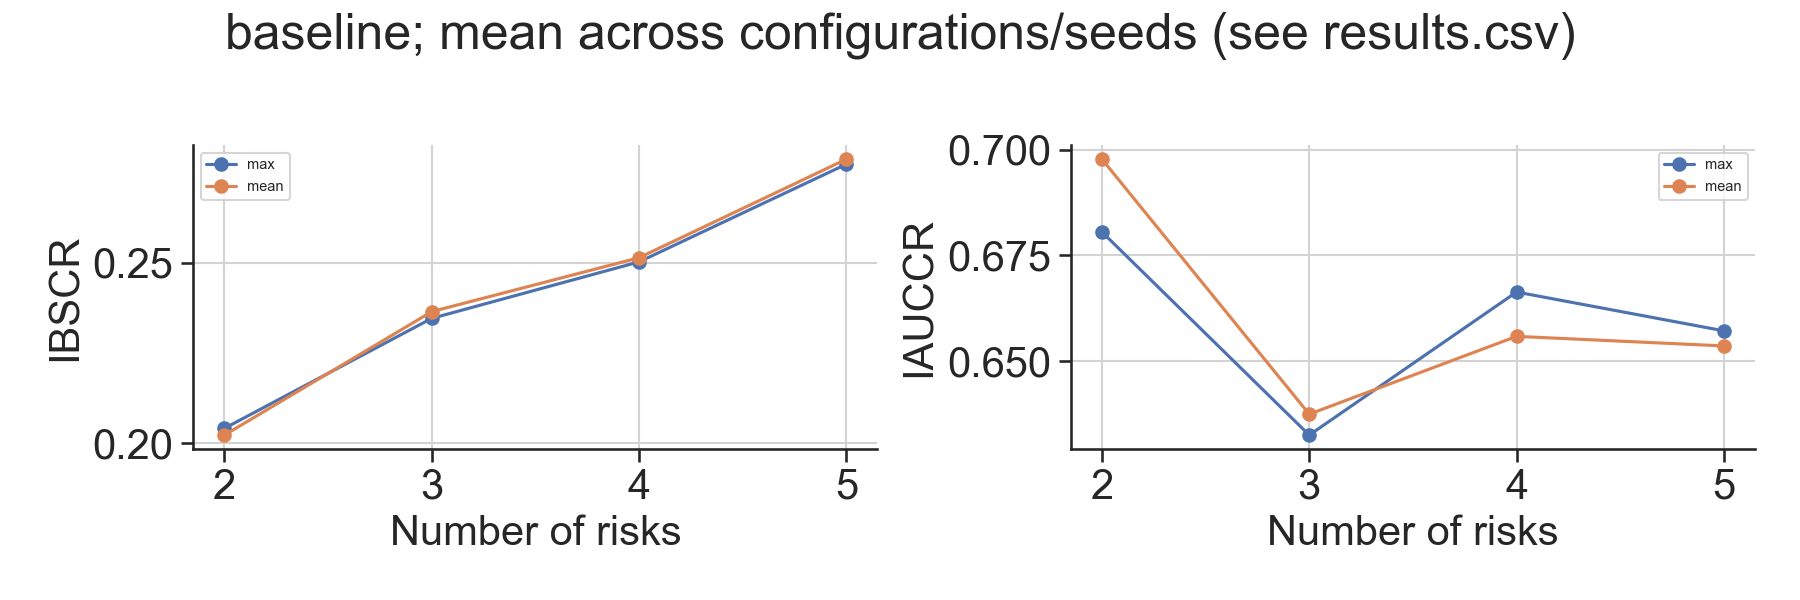

**multicriteria_quality**

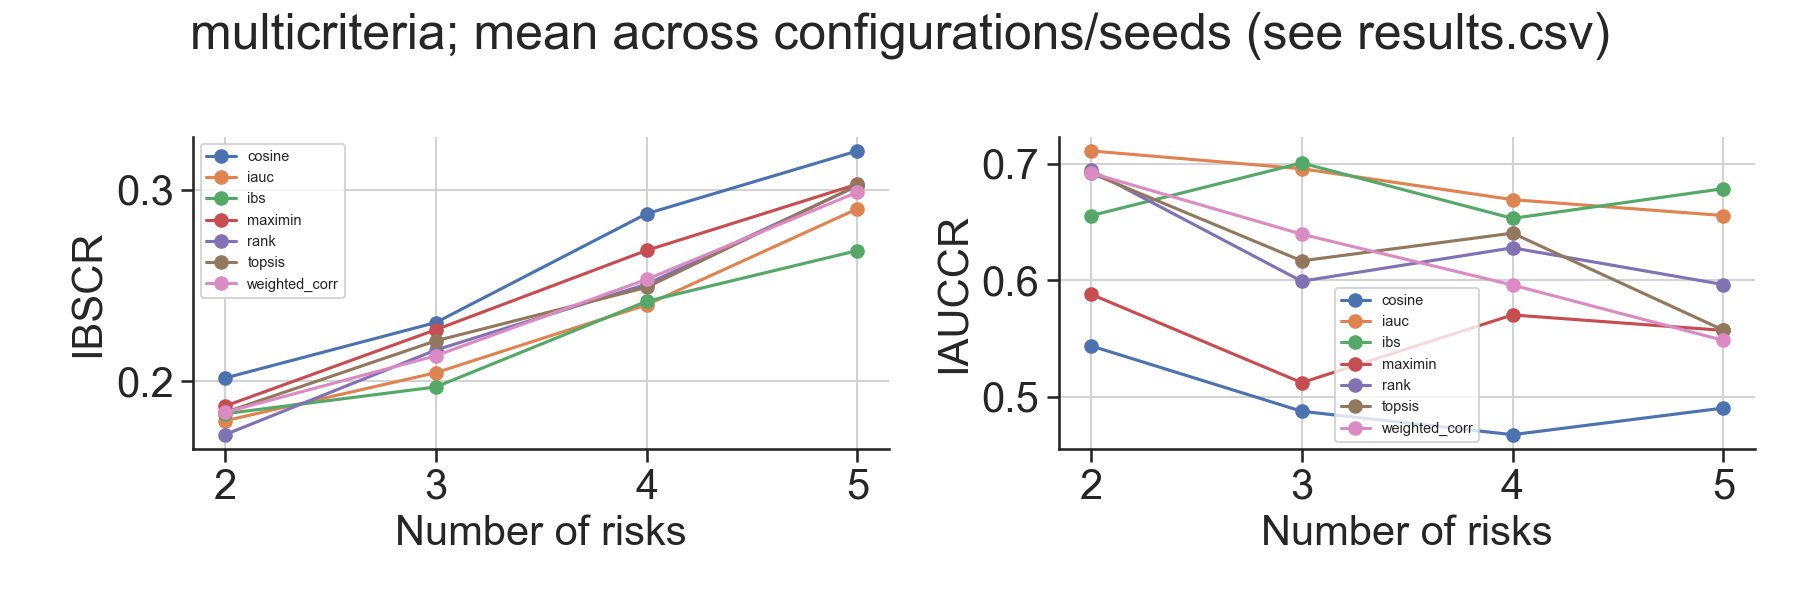

**ensemble_quality**

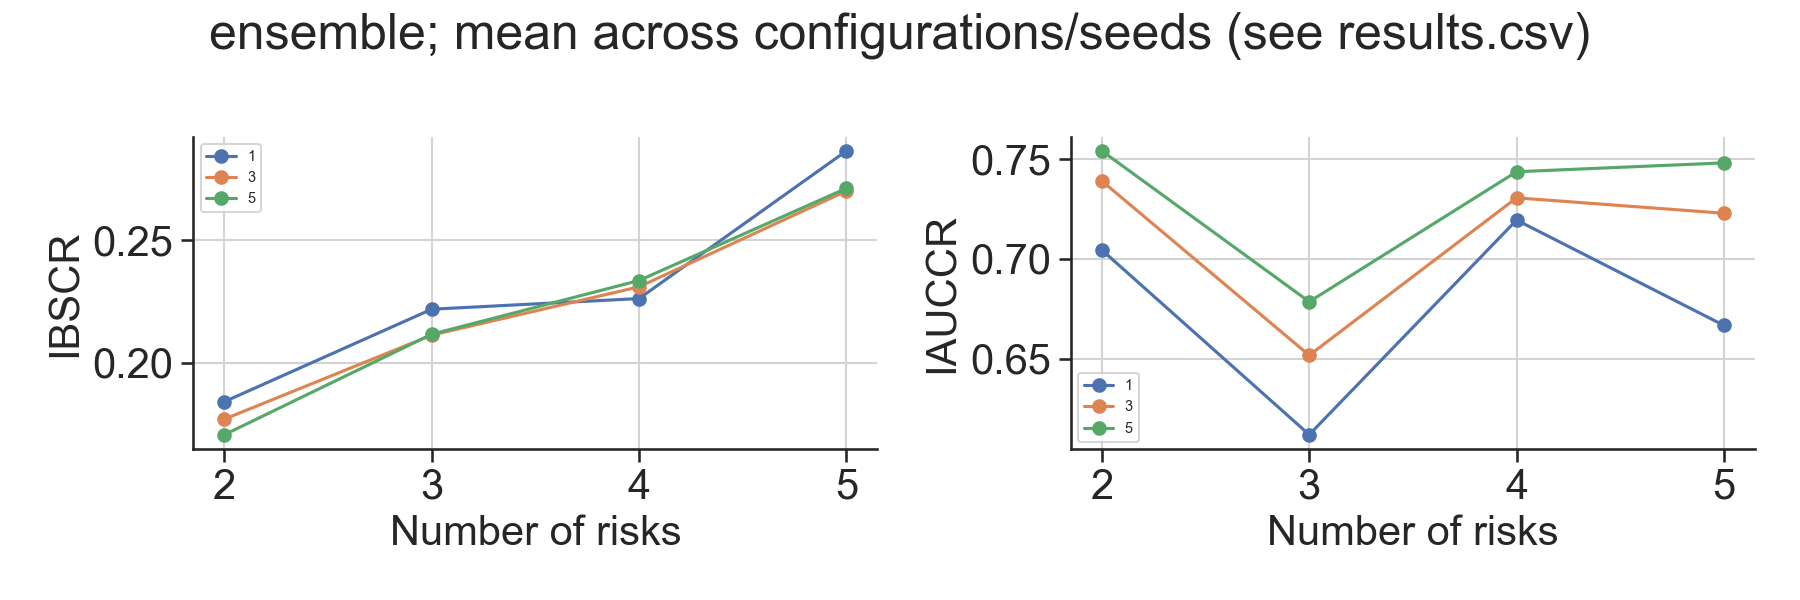

**ensemble_size_quality**

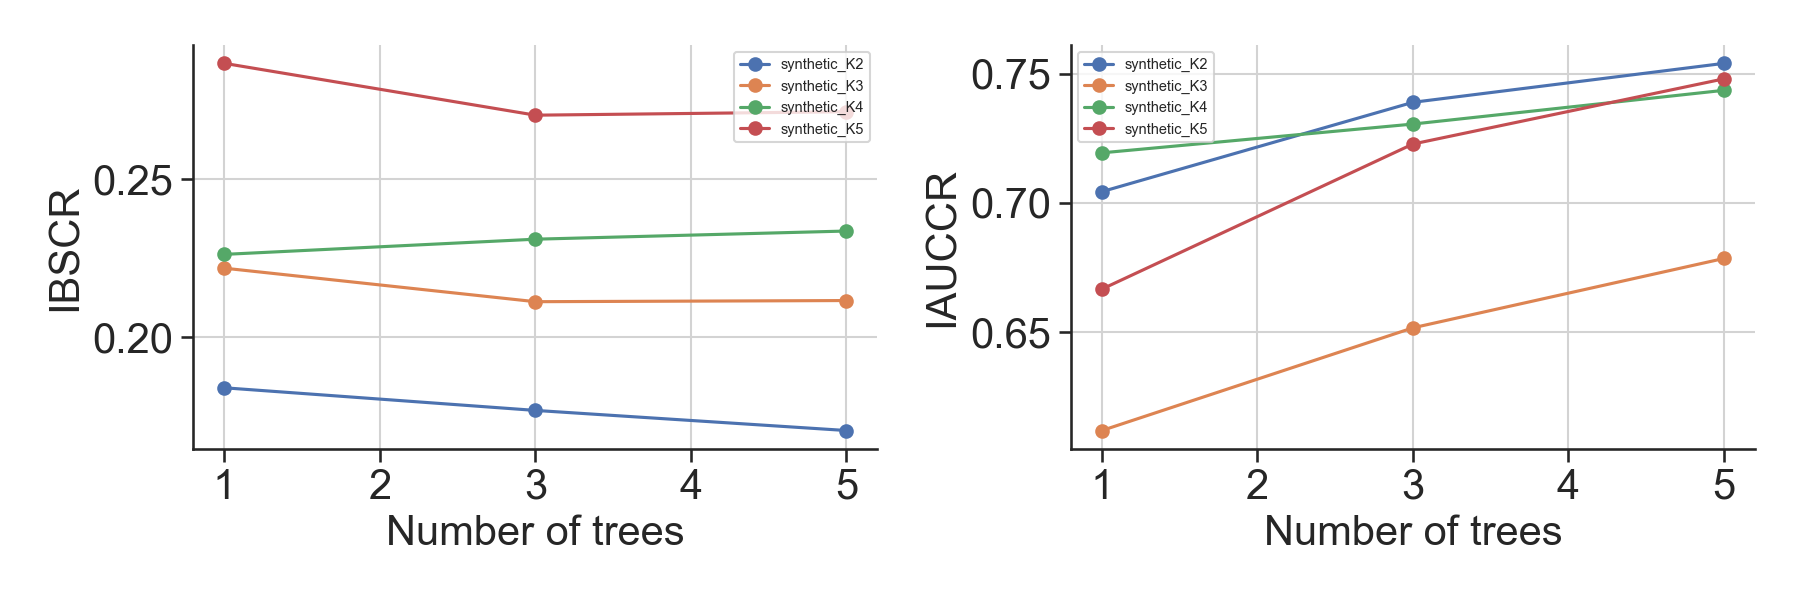

### 各风险数量的 KM 生存树

**synthetic_K2_seed42_KM_tree**

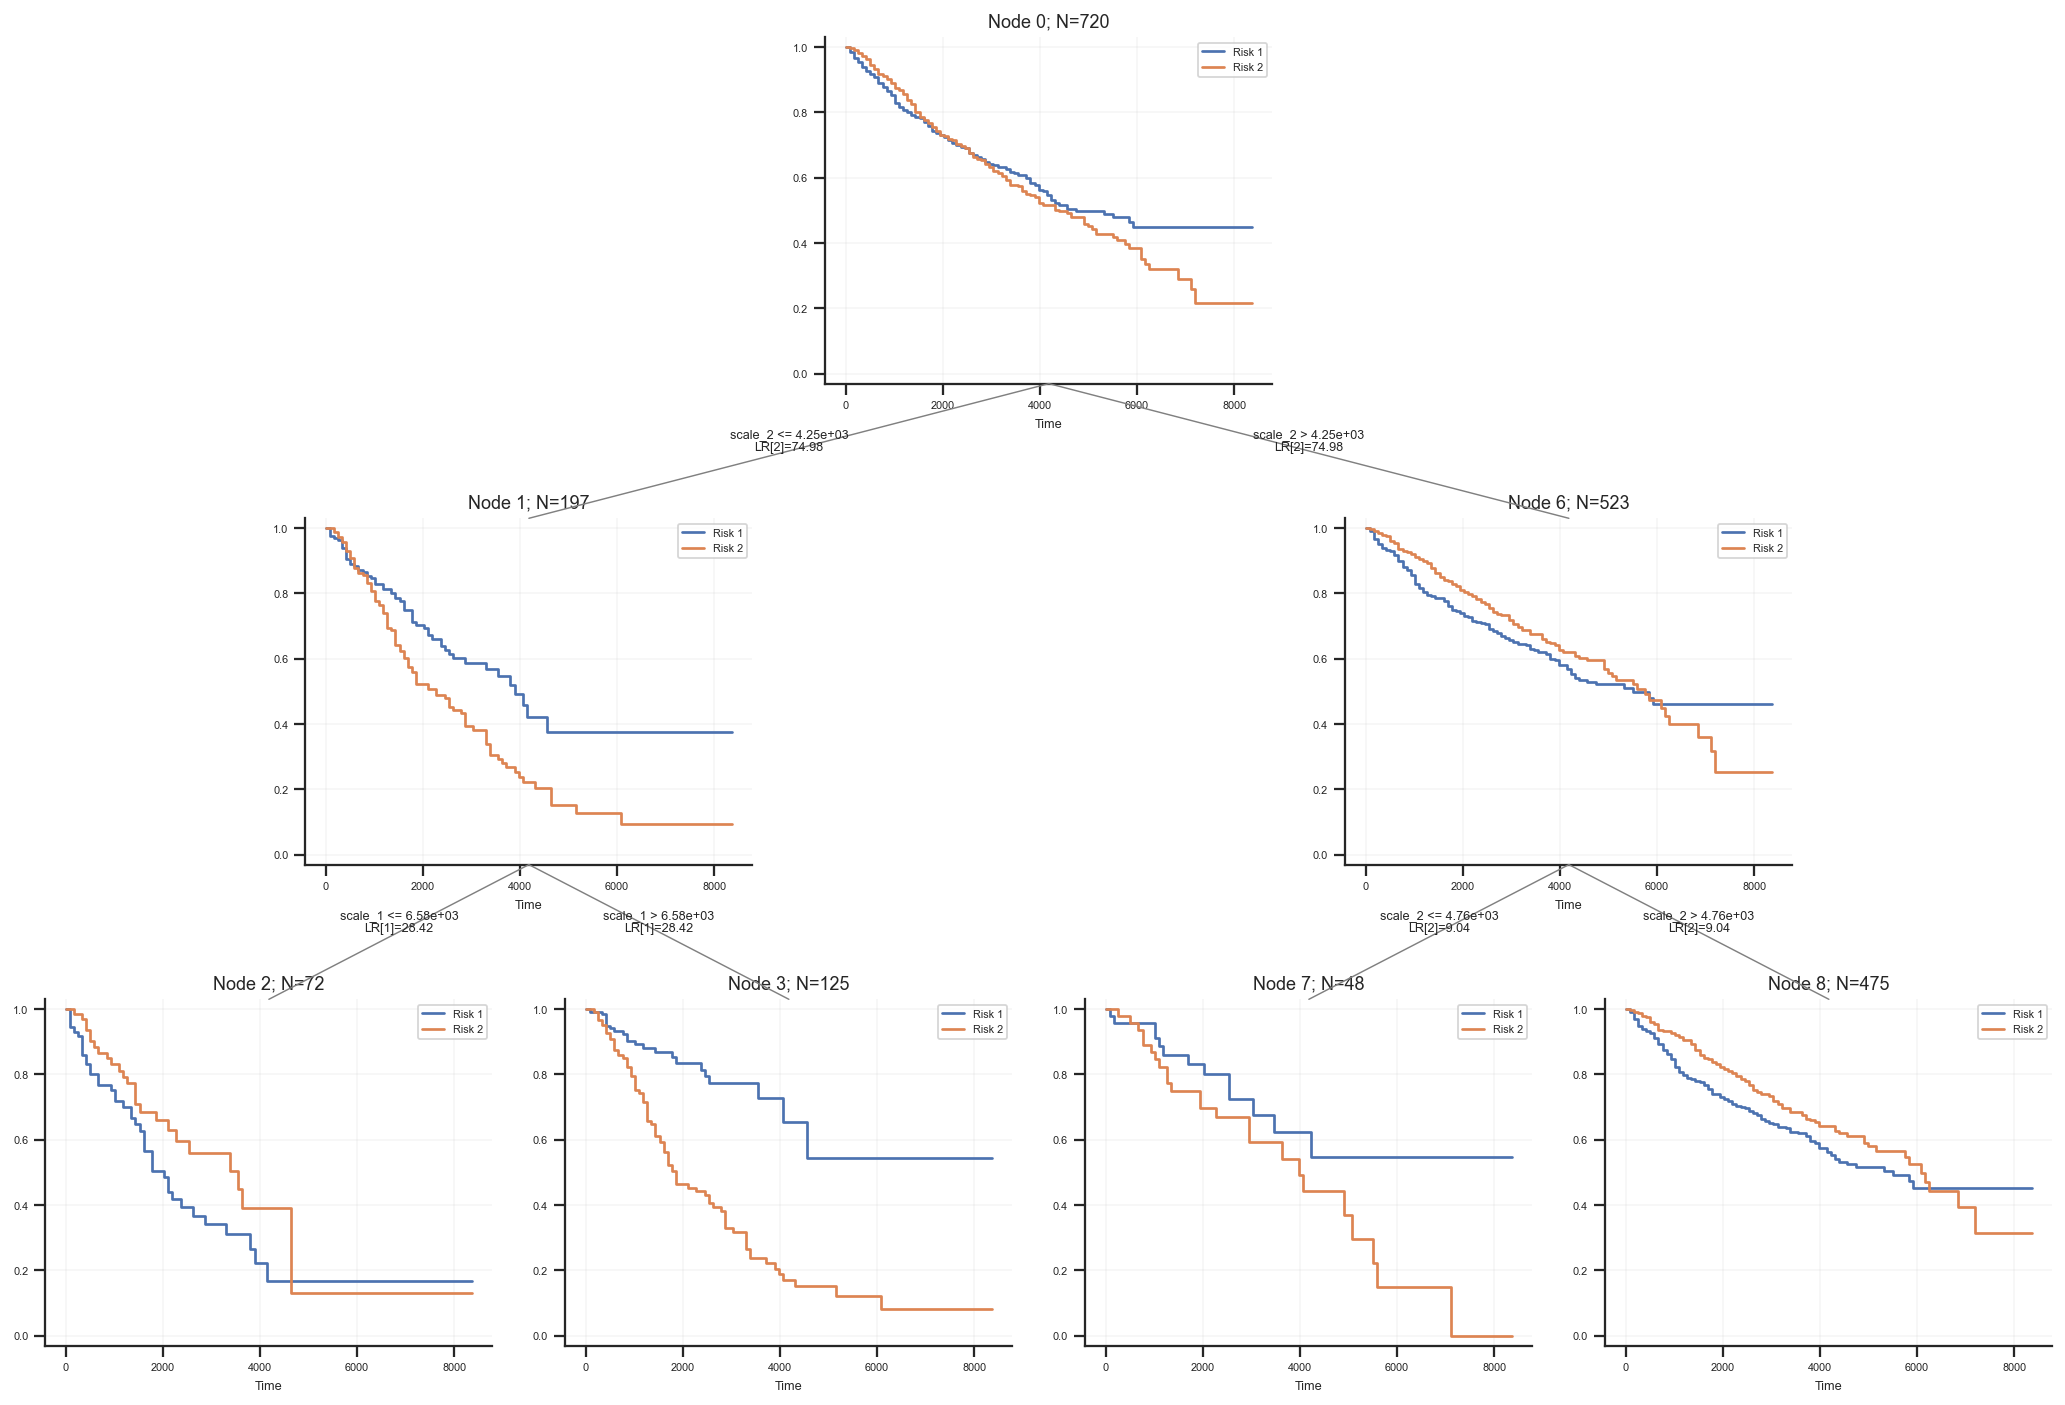

**synthetic_K3_seed42_KM_tree**

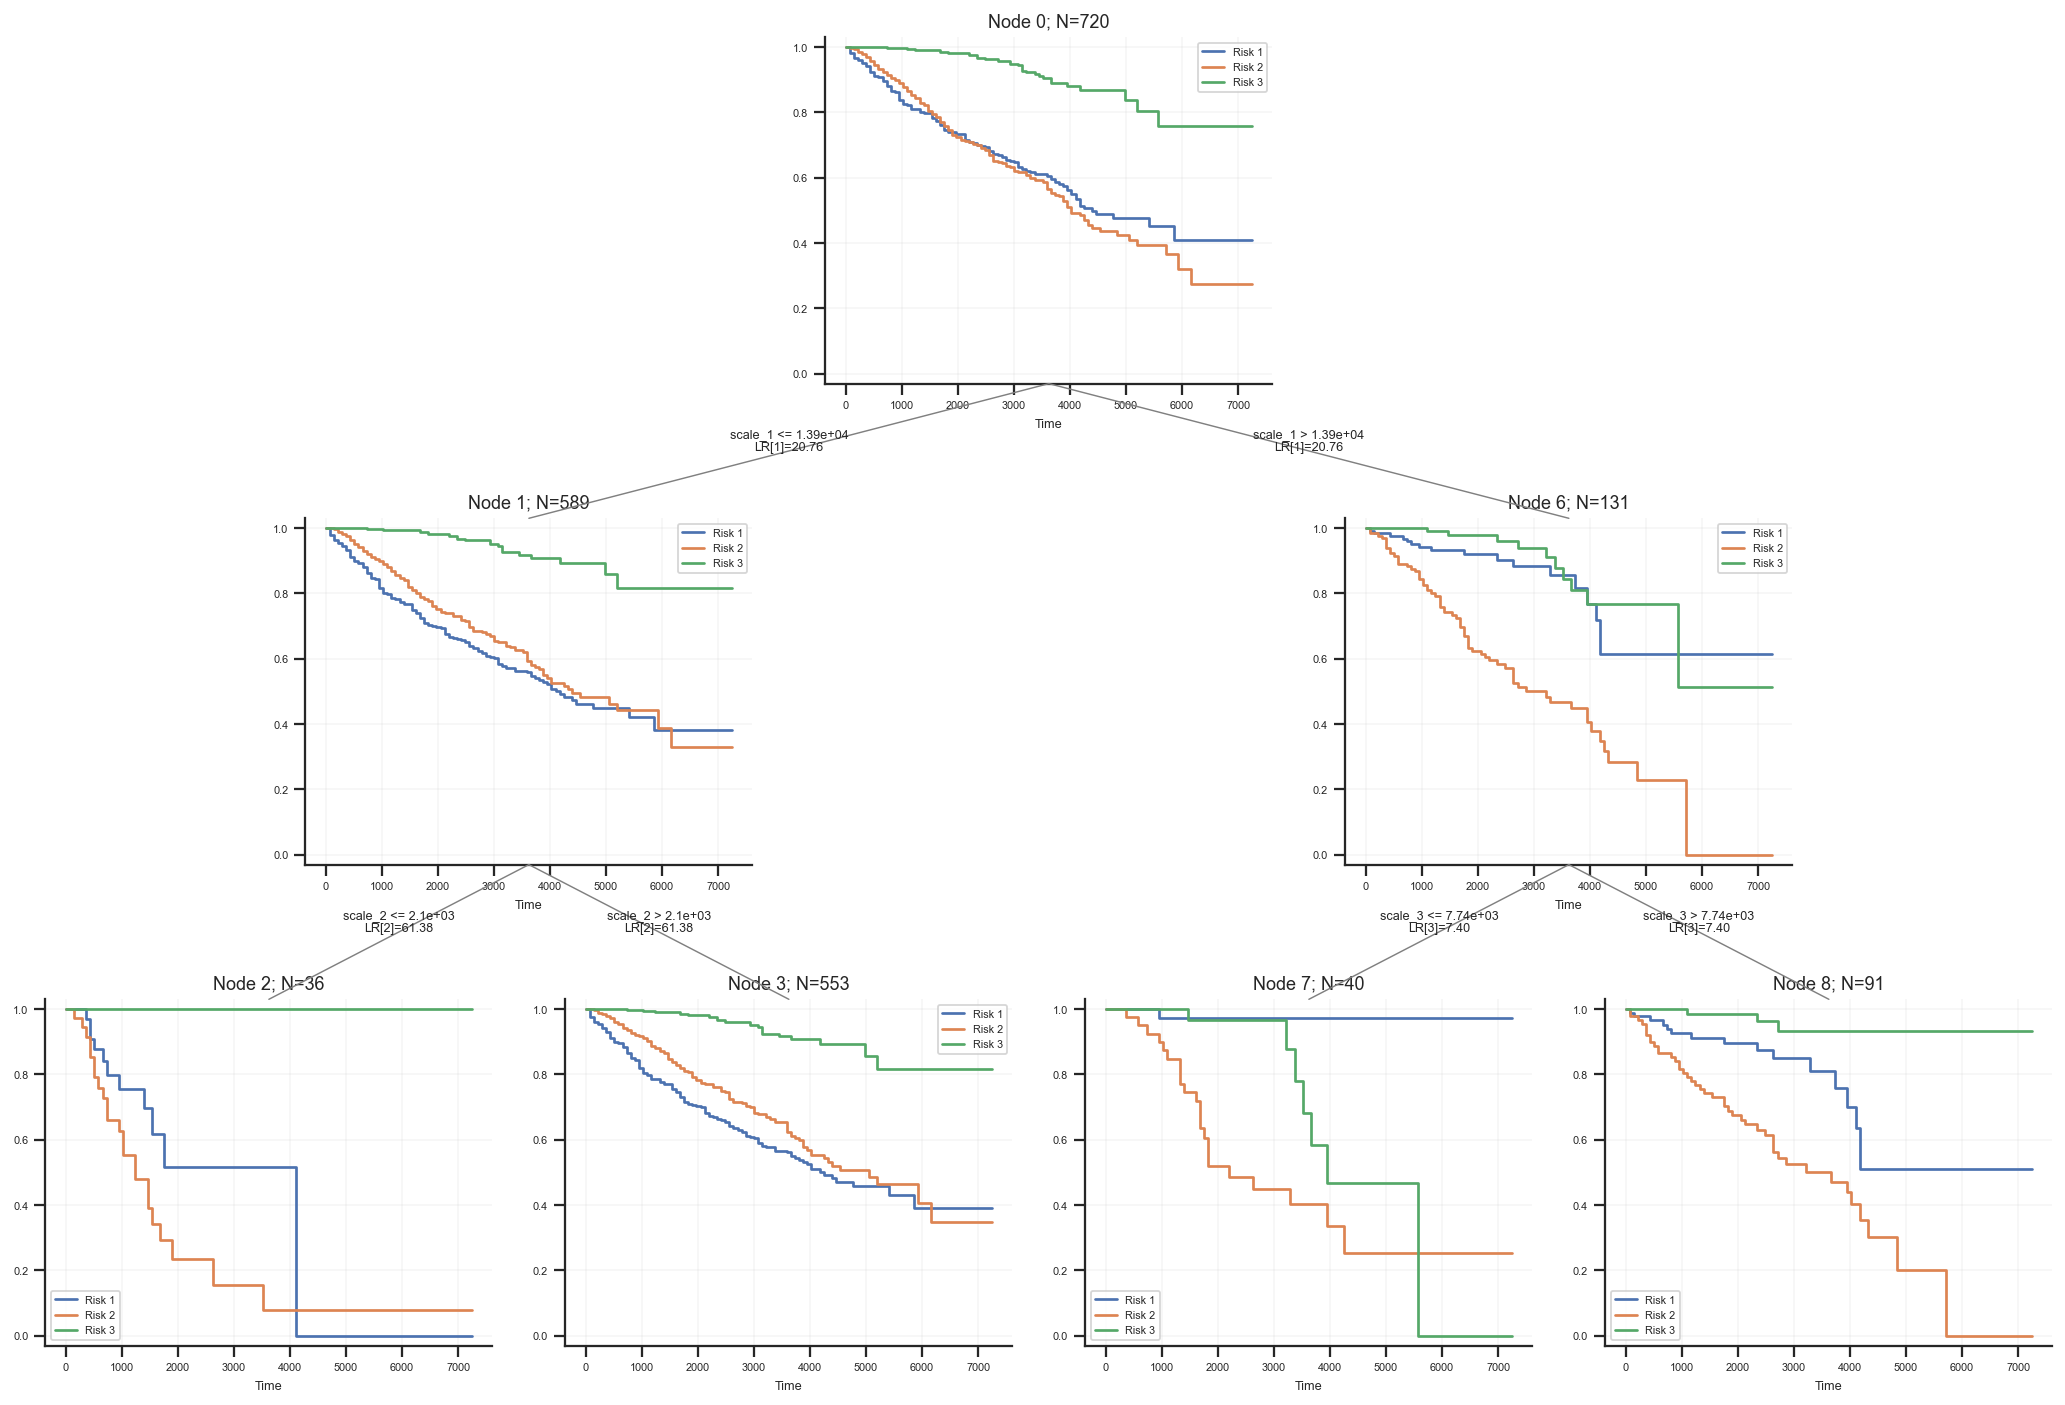

**synthetic_K4_seed42_KM_tree**

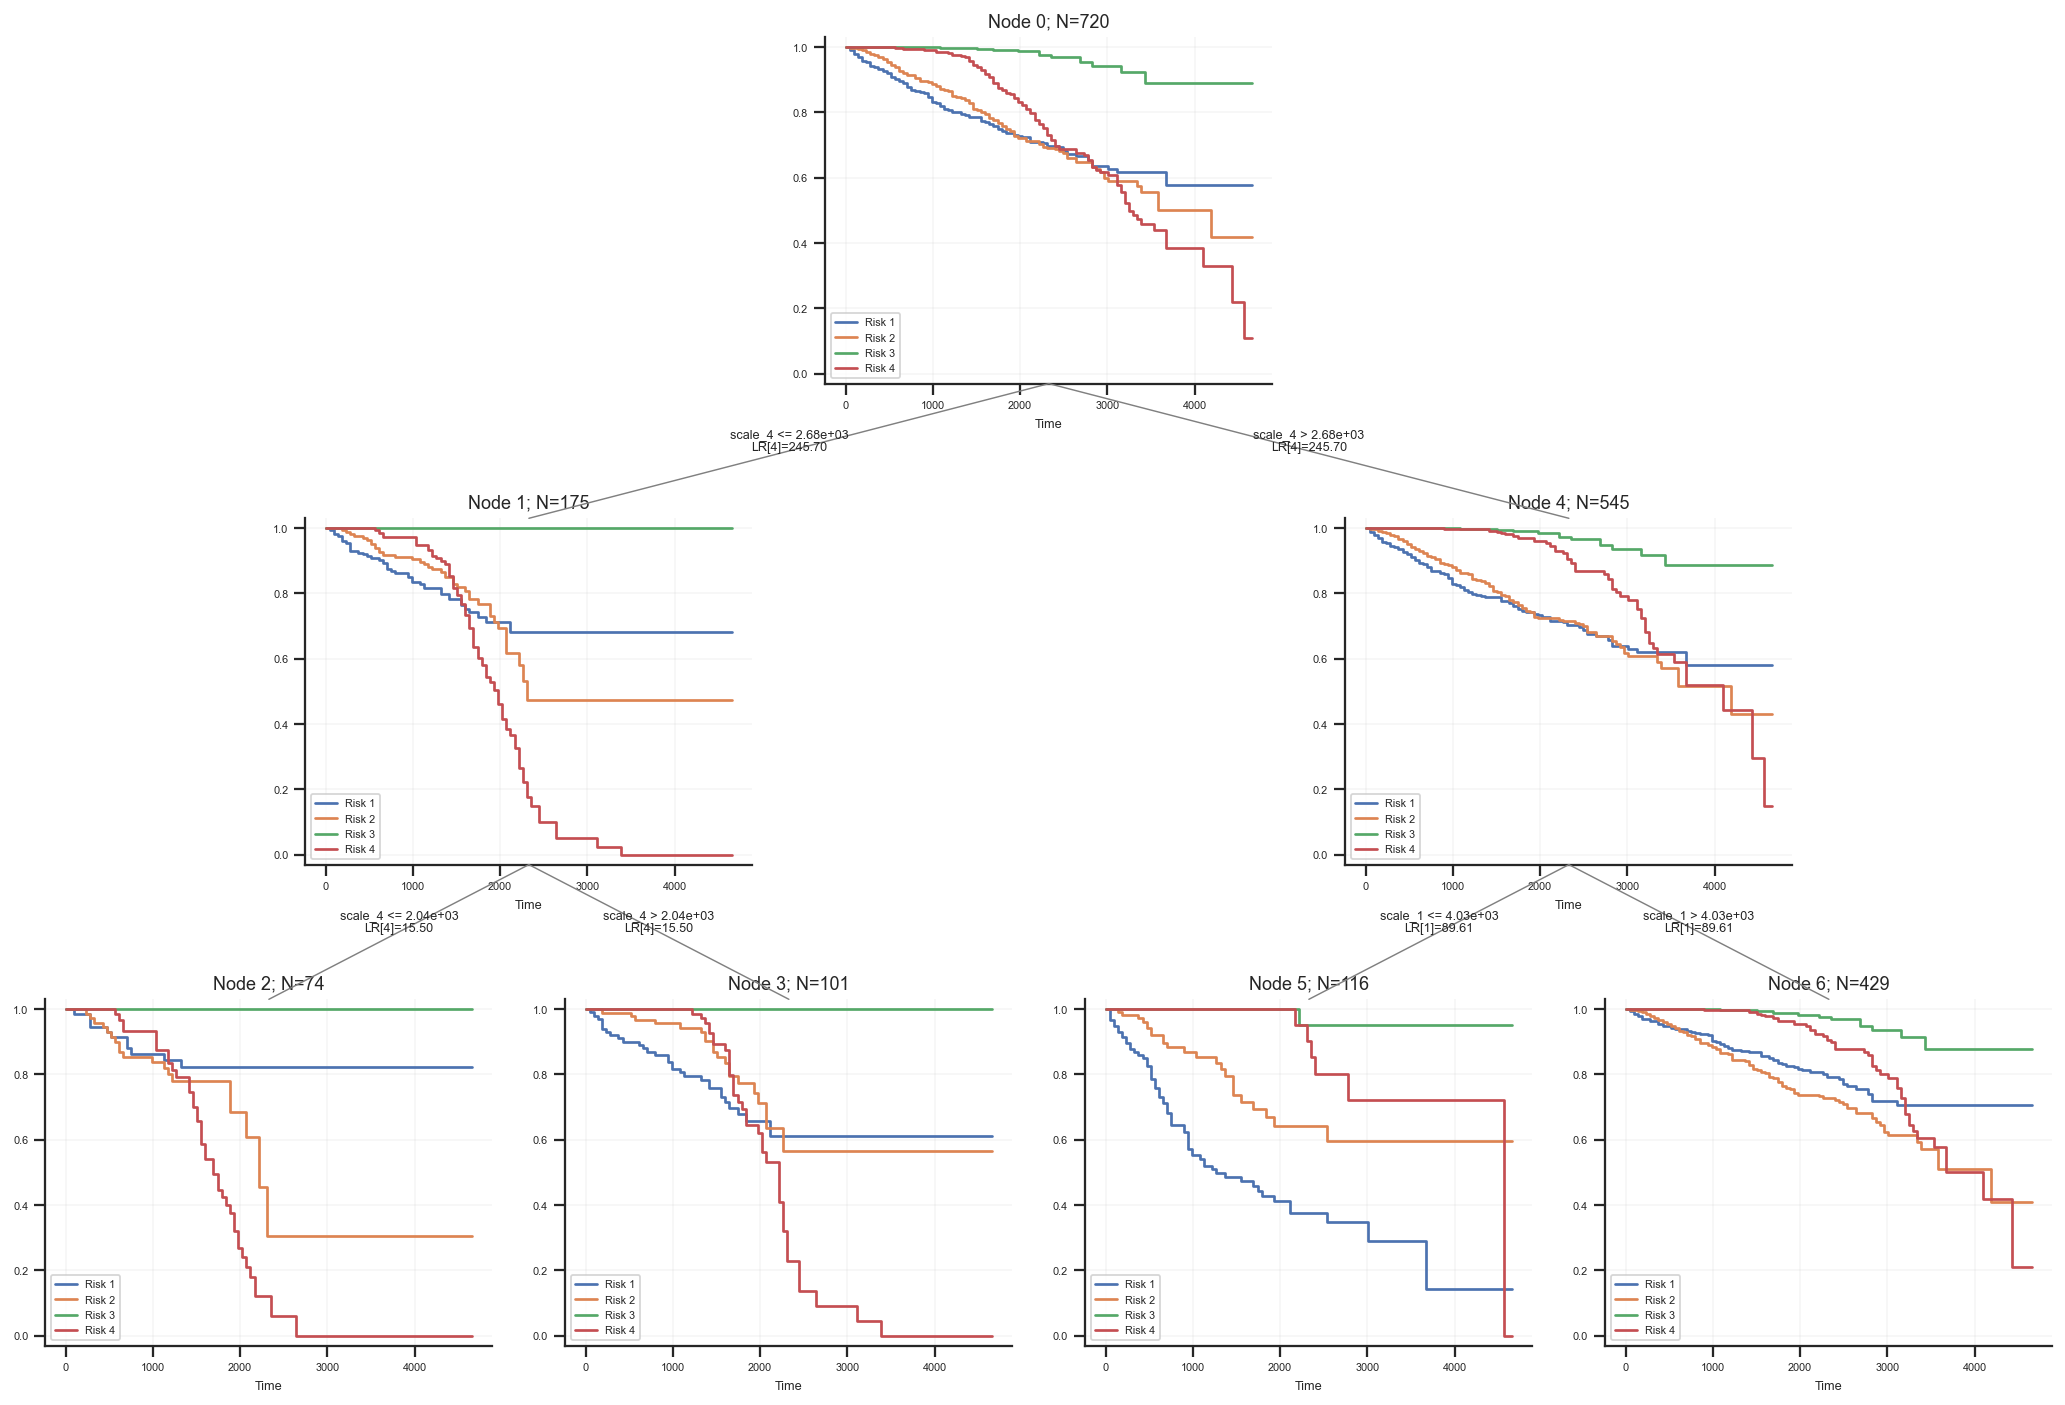

**synthetic_K5_seed42_KM_tree**

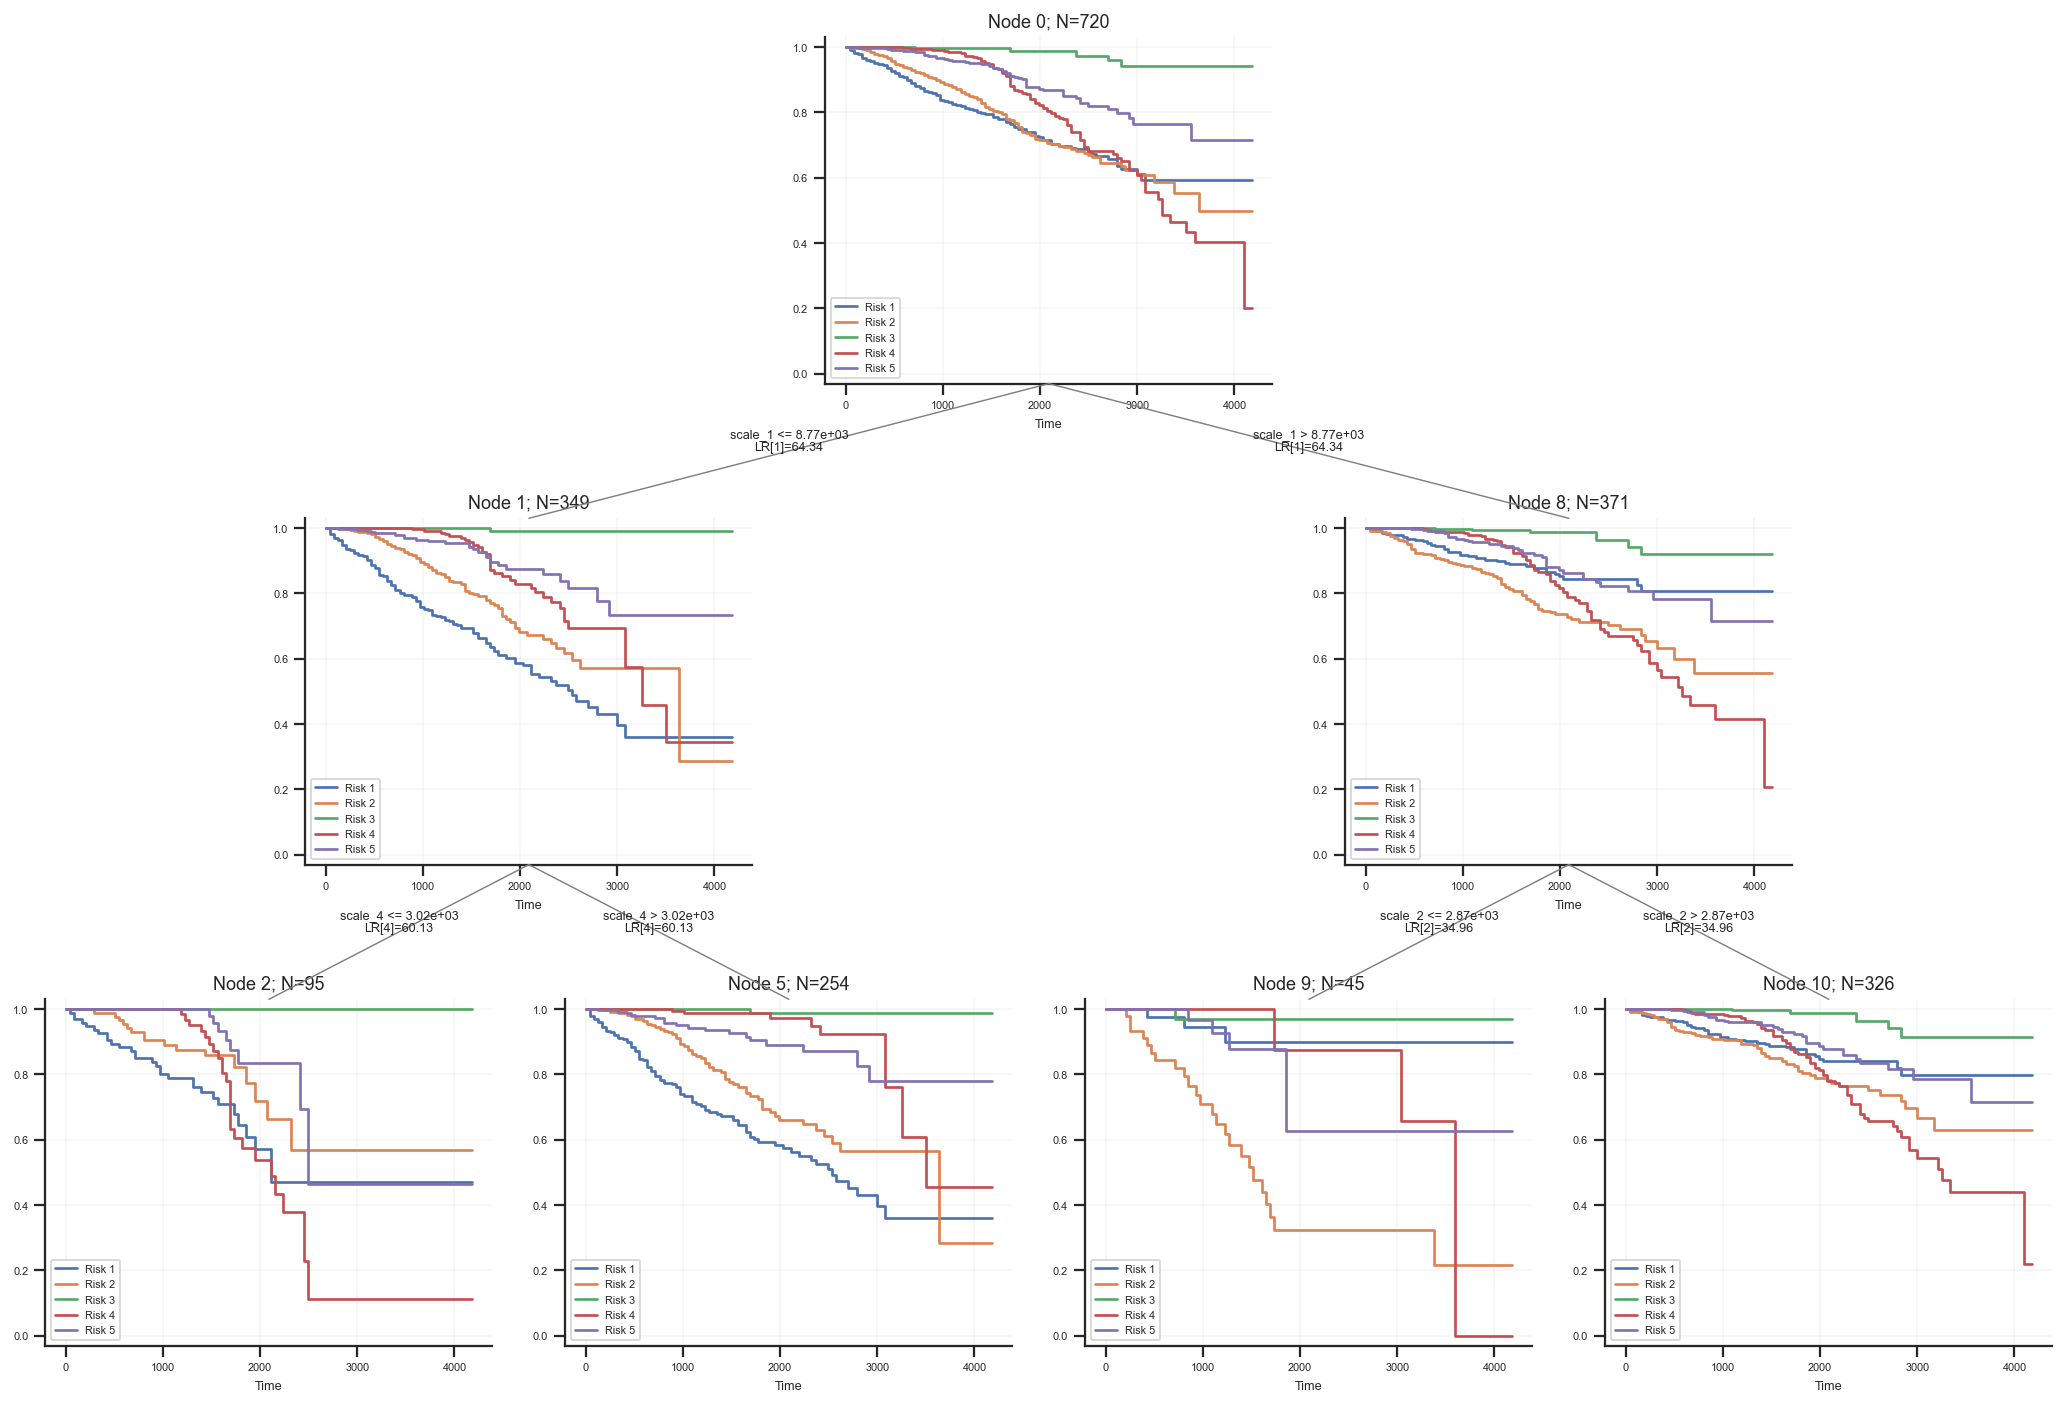

### 各特征候选分裂空间

**feature_1_PCA**

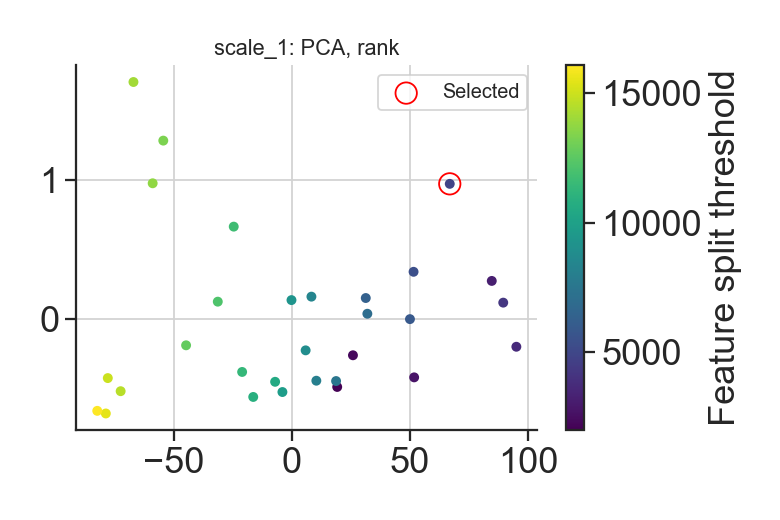

**feature_1_tSNE**

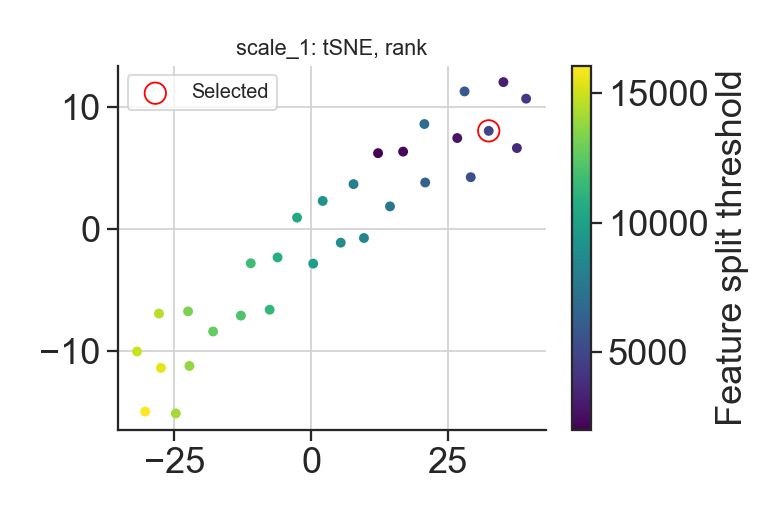

**feature_2_PCA**

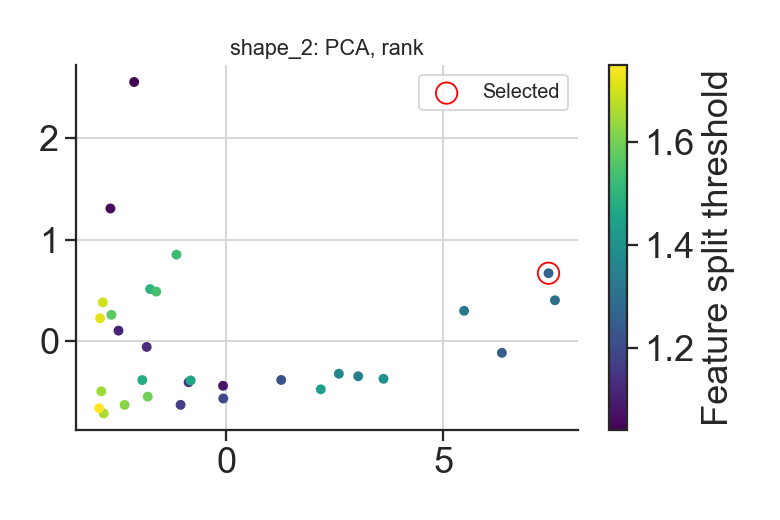

**feature_2_tSNE**

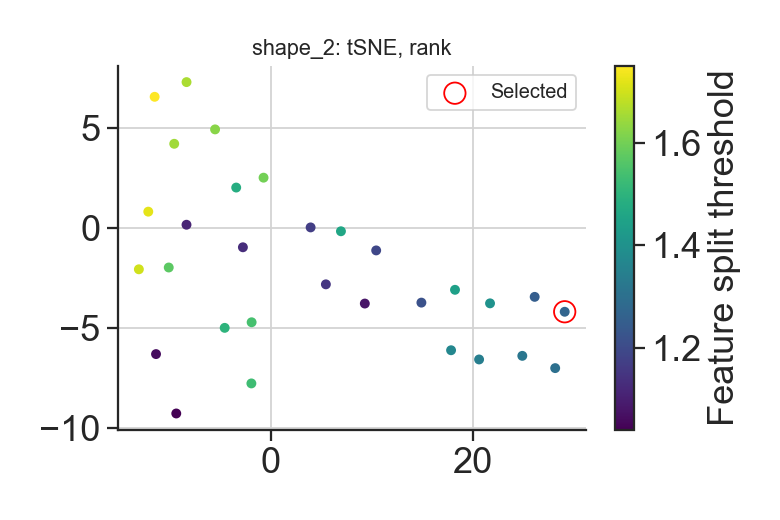

**feature_3_PCA**

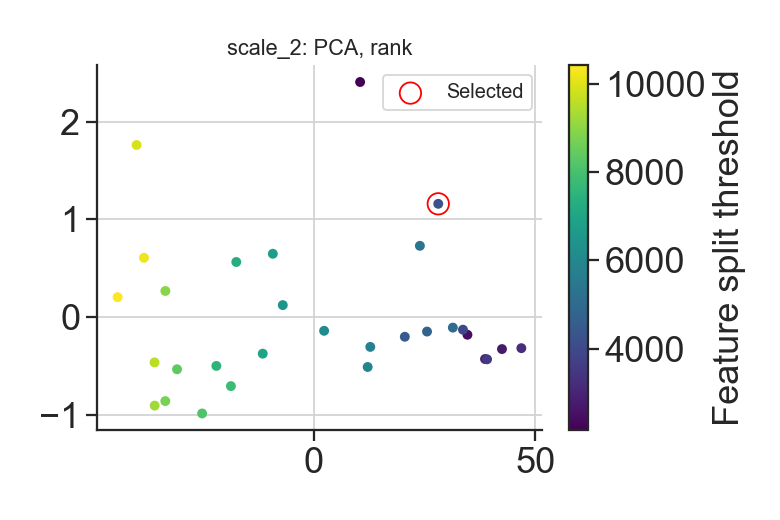

**feature_3_tSNE**

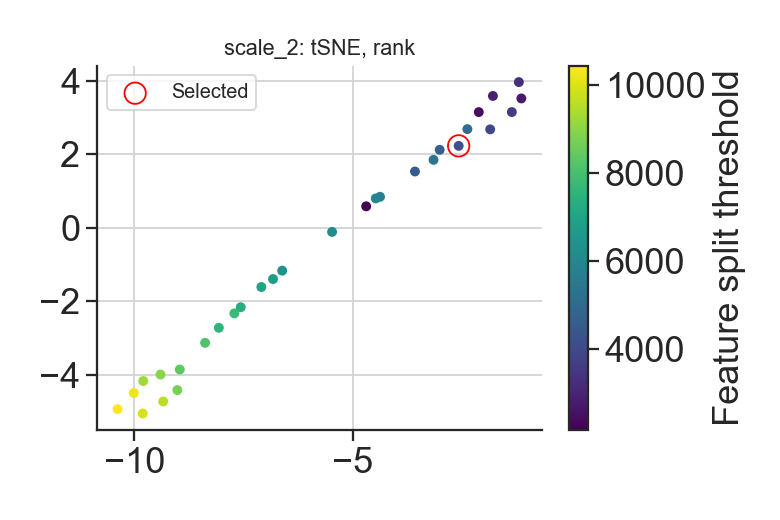

### 跨特征最佳分裂比较

**between_features_PCA**

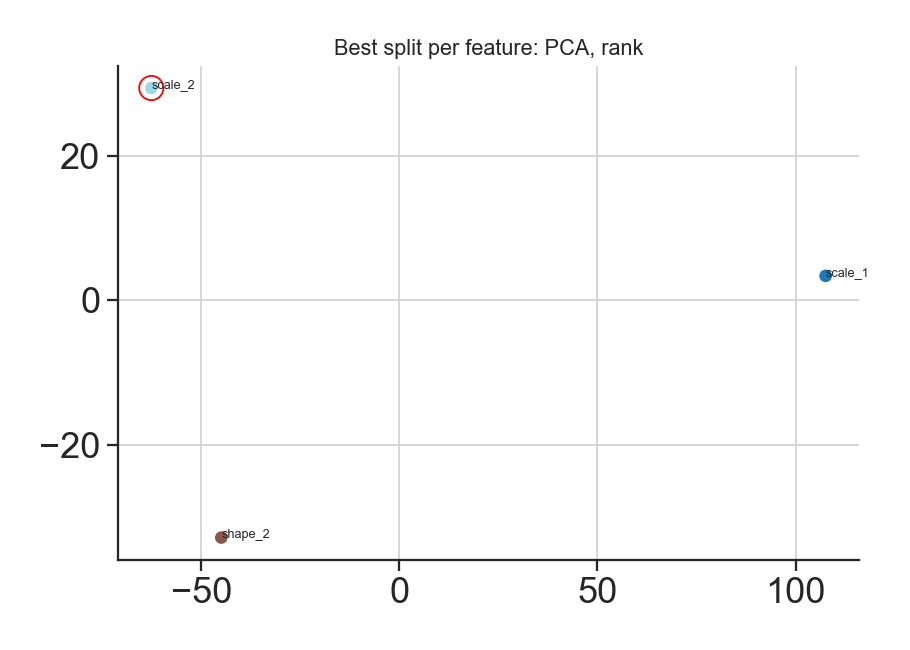

**between_features_tSNE**

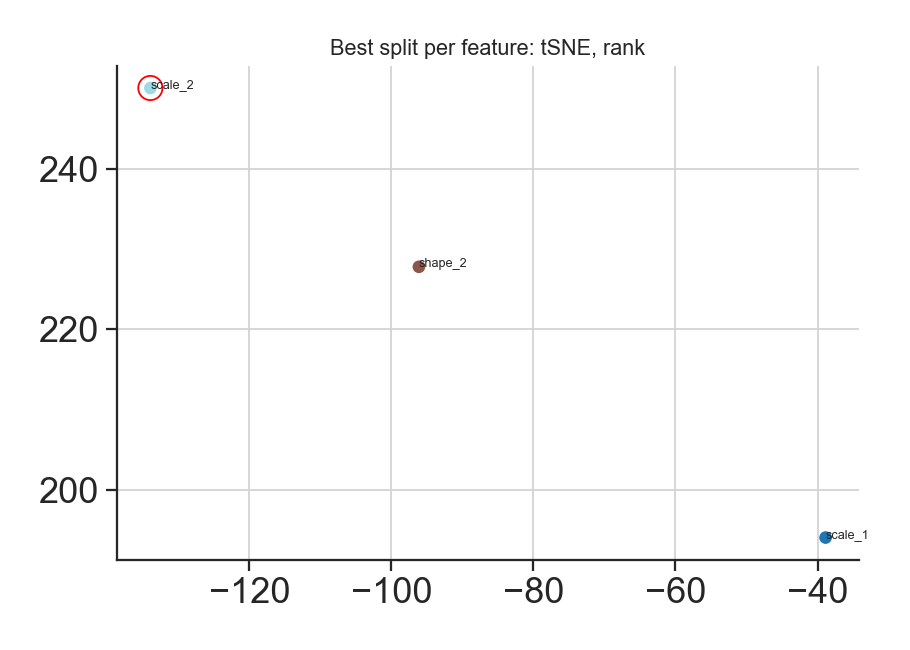

已展示 16 张图片。此输出使用现有实验图片，未重新训练。


In [6]:
# 本格只读取和展示已生成的图片，不重新训练模型。
from pathlib import Path
from IPython.display import Image, Markdown, display

if 'RESULT_DIR' in globals():
    gallery_dir = Path(RESULT_DIR)
else:
    gallery_base = Path.cwd()
    if (gallery_base / 'KM_Coursework').is_dir():
        gallery_base = gallery_base / 'KM_Coursework'
    gallery_dir = gallery_base / 'validation_results_notebook'
    if not gallery_dir.exists():
        gallery_dir = gallery_base / 'validation_results'

groups = [
    ('性能比较：IBSCR 越低越好，IAUCCR 越高越好', [
        ('baseline_quality.png', 'max/mean 单树方法随风险数量的表现'),
        ('multicriteria_quality.png', '多准则分裂方法随风险数量的表现'),
        ('ensemble_quality.png', '不同集成规模随风险数量的表现'),
        ('ensemble_size_quality.png', '增加树的数量对预测质量的影响'),
    ]),
    ('KM 生存树：每种风险各一条生存曲线',
     [(p.name, p.stem) for p in sorted(gallery_dir.glob('*_KM_tree.png'))]),
    ('分裂空间：每个点是一种候选分裂，颜色为阈值，红圈为选中项',
     [(str(p.relative_to(gallery_dir)), p.stem) for p in sorted((gallery_dir / 'geometry').glob('feature_*.png'))]),
    ('跨特征比较：每个点是某个特征的最佳候选分裂',
     [(str(p.relative_to(gallery_dir)), p.stem) for p in sorted((gallery_dir / 'geometry').glob('between_features_*.png'))]),
]
shown = 0
for heading, entries in groups:
    display(Markdown('### ' + heading))
    for filename, caption in entries:
        picture = gallery_dir / filename
        if picture.exists():
            display(Markdown('**' + caption + '**'))
            display(Image(filename=str(picture), width=1000))
            shown += 1
if not shown:
    print('还没有图片，请先运行实验单元；当前目录：', gallery_dir)
else:
    print(f'已展示 {shown} 张图片；文件副本仍保存在：{gallery_dir}')


## 5. 如何确认完成

查看 `run_metadata.json`、`results.csv` 和 `verification.json`。失败行包含完整 traceback，NaN 指标保留为 NaN，不填充为“成功分数”。数据预处理、风险标签、时间网格和超参数均在当前运行内重建，不依赖旧内核变量。原 Notebook 保留在原位置。
